# Лабораторная работа № 4. Визуализация данных

**Тема:** «Разработка программного продукта бота для определения сорта стекла»

**Исходные данные:** Kaggle — [uciml/glass](https://www.kaggle.com/uciml/glass) (Glass Identification Data Set: 214 образцов стекла, 9 признаков — показатель преломления RI и содержание оксидов Na, Mg, Al, Si, K, Ca, Ba, Fe; целевая переменная `Type` — сорт стекла).

## Цель работы
Построить графики для разведочного анализа данных о стекле: гистограммы, «ящики с усами», тепловую карту и другие типы диаграмм (Matplotlib, Seaborn, Plotly).

## Домашнее задание
1. Загрузить выборку с сайта Kaggle.com.
2. Изучить документацию matplotlib, построить некоторые другие типы графиков.
3. Построить гистограмму распределения по каждому показателю.
4. Построить ящик с усами для выявления выбросов по показателю.
5. Построить тепловую карту и сделать вывод о зависимости между показателями.

### 1. Загрузка выборки (Kaggle uciml/glass)

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

URL  = "https://archive.ics.uci.edu/ml/machine-learning-databases/glass/glass.data"
COLS = ["Id", "RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "Type"]
FEATURES = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
TYPE_NAMES = {1: "окна зданий (float)", 2: "окна зданий (non-float)",
              3: "окна авто (float)", 5: "контейнеры",
              6: "посуда", 7: "фары"}

def load_glass():
    """Набор Kaggle uciml/glass (glass.csv). Если файл не загружен в Colab,
    берём тот же набор из репозитория UCI."""
    if os.path.exists("glass.csv"):
        return pd.read_csv("glass.csv")
    return pd.read_csv(URL, names=COLS).drop(columns="Id")

df = load_glass()

print(df.shape)
display(df.head())

(214, 10)


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


### 2. Другие типы графиков Matplotlib / Seaborn

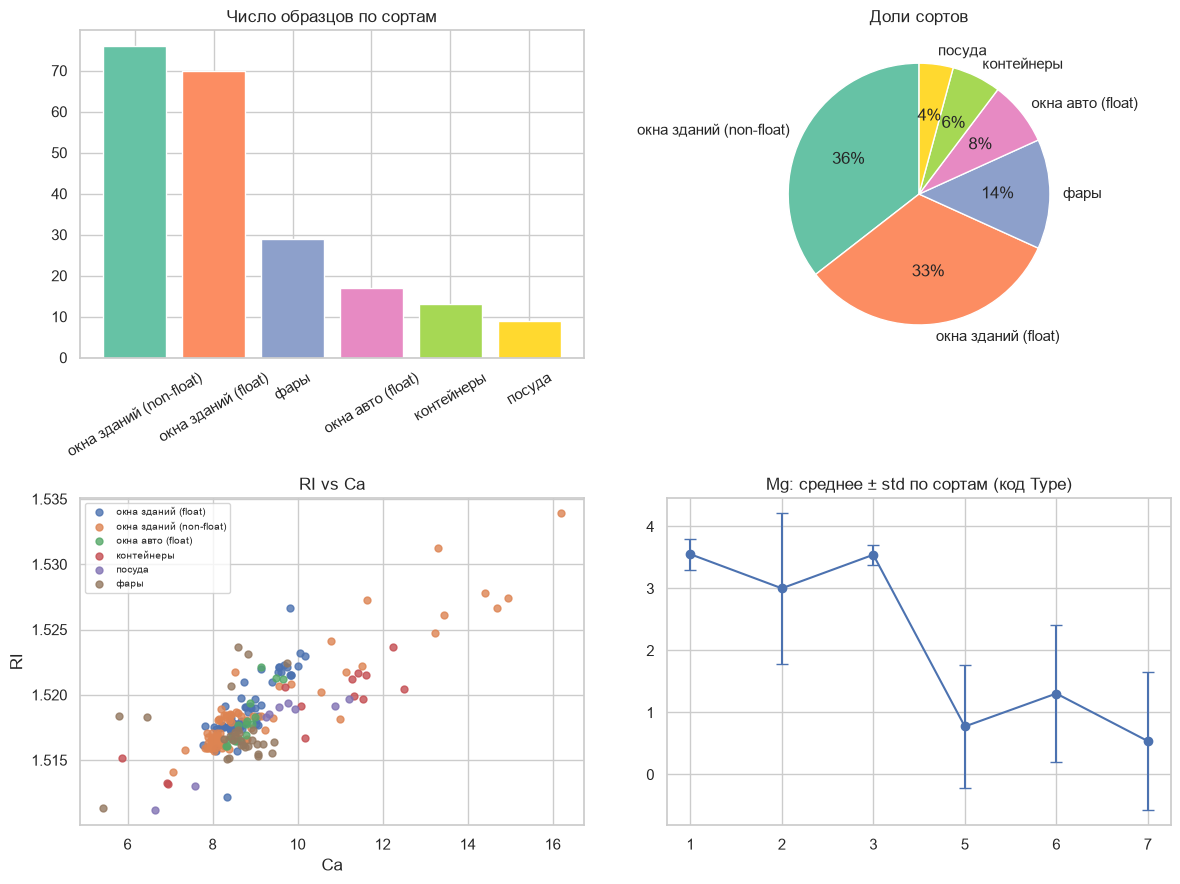

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
# столбчатая диаграмма — число образцов по сортам
vc = df["Type"].map(TYPE_NAMES).value_counts()
ax[0, 0].bar(vc.index, vc.values, color=sns.color_palette("Set2", len(vc))); ax[0, 0].set_title("Число образцов по сортам")
ax[0, 0].tick_params(axis="x", rotation=30)
# круговая диаграмма долей
ax[0, 1].pie(vc.values, labels=vc.index, autopct="%1.0f%%", startangle=90, colors=sns.color_palette("Set2", len(vc))); ax[0, 1].set_title("Доли сортов")
# диаграмма рассеяния RI-Ca с цветом по сорту
for t, g in df.groupby("Type"):
    ax[1, 0].scatter(g["Ca"], g["RI"], label=TYPE_NAMES[t], s=25, alpha=.8)
ax[1, 0].set_xlabel("Ca"); ax[1, 0].set_ylabel("RI"); ax[1, 0].set_title("RI vs Ca"); ax[1, 0].legend(fontsize=7)
# график средних значений Mg по сортам с планками ошибок (std)
m = df.groupby("Type")["Mg"].agg(["mean", "std"])
ax[1, 1].errorbar(m.index.astype(str), m["mean"], yerr=m["std"], fmt="o-", capsize=4); ax[1, 1].set_title("Mg: среднее ± std по сортам (код Type)")
plt.tight_layout(); plt.show()

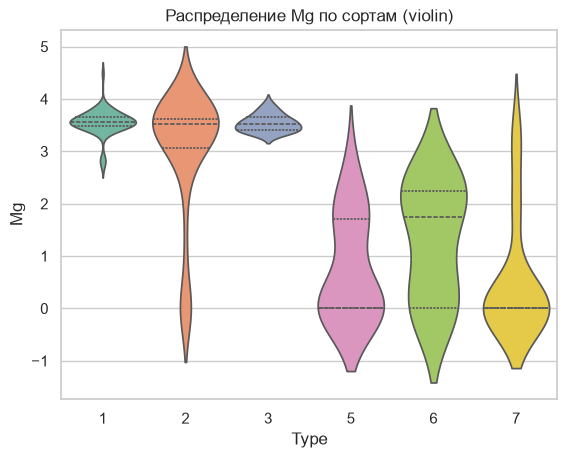

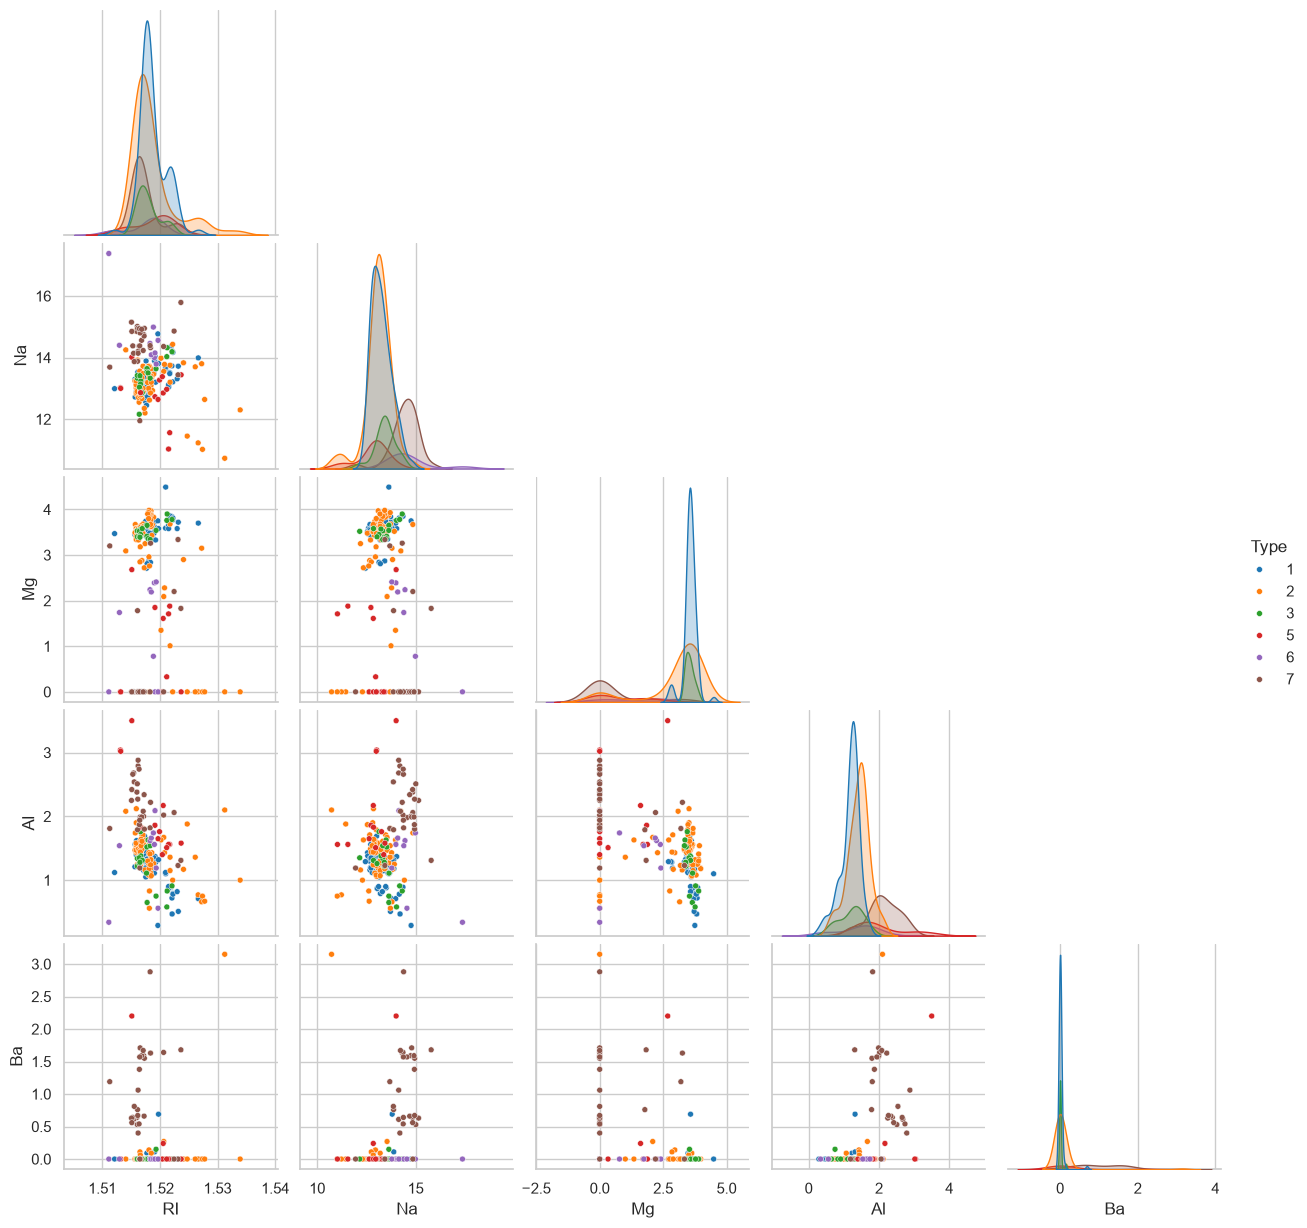

In [ ]:
sns.violinplot(data=df, x="Type", y="Mg", palette="Set2", inner="quartile"); plt.title("Распределение Mg по сортам (violin)"); plt.show()
sns.pairplot(df[["RI", "Na", "Mg", "Al", "Ba", "Type"]], hue="Type", palette="tab10", corner=True, plot_kws={"s": 18}); plt.show()

### 3. Гистограмма распределения по каждому показателю

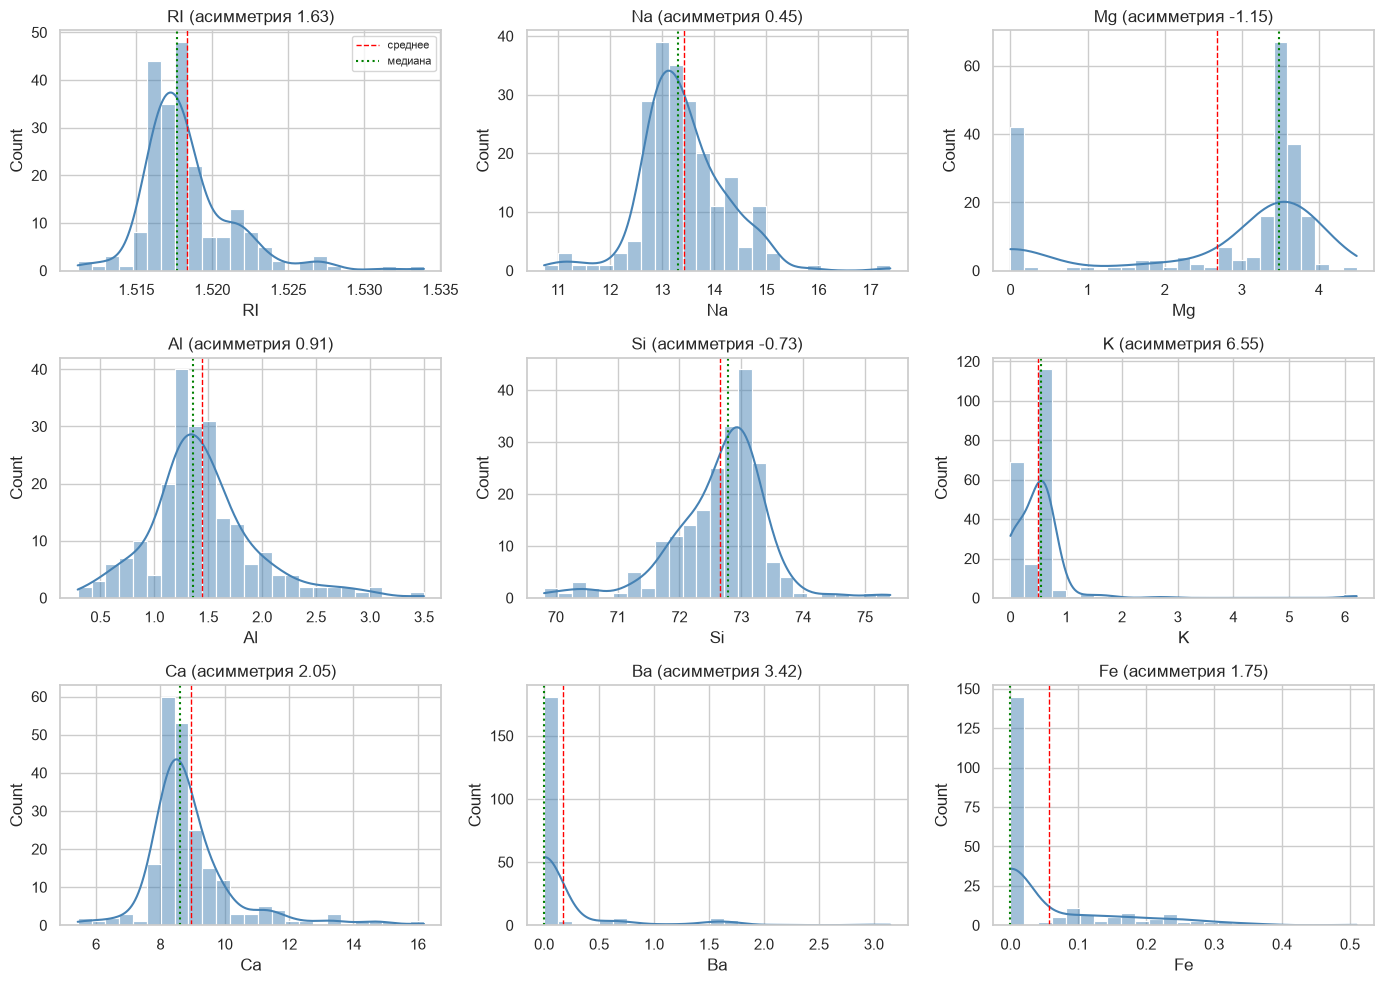

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for a, f in zip(axes.ravel(), FEATURES):
    sns.histplot(df[f], bins=25, kde=True, ax=a, color="steelblue")
    a.axvline(df[f].mean(), color="red", ls="--", lw=1, label="среднее"); a.axvline(df[f].median(), color="green", ls=":", lw=1.5, label="медиана")
    a.set_title(f"{f} (асимметрия {df[f].skew():.2f})")
axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Вывод по гистограммам.** RI, Na, Al, Si и Ca имеют колоколообразную, близкую к нормальной форму (с лёгким правым скосом у RI, Na, Ca). Mg имеет бимодальное распределение: пик около нуля (фары, контейнеры, посуда) и пик около 3.5 % (окна). Ba, Fe и K резко скошены вправо: большинство значений — нули или близкие к ним, а редкие большие значения образуют «хвост».

### 4. Ящик с усами (выбросы)

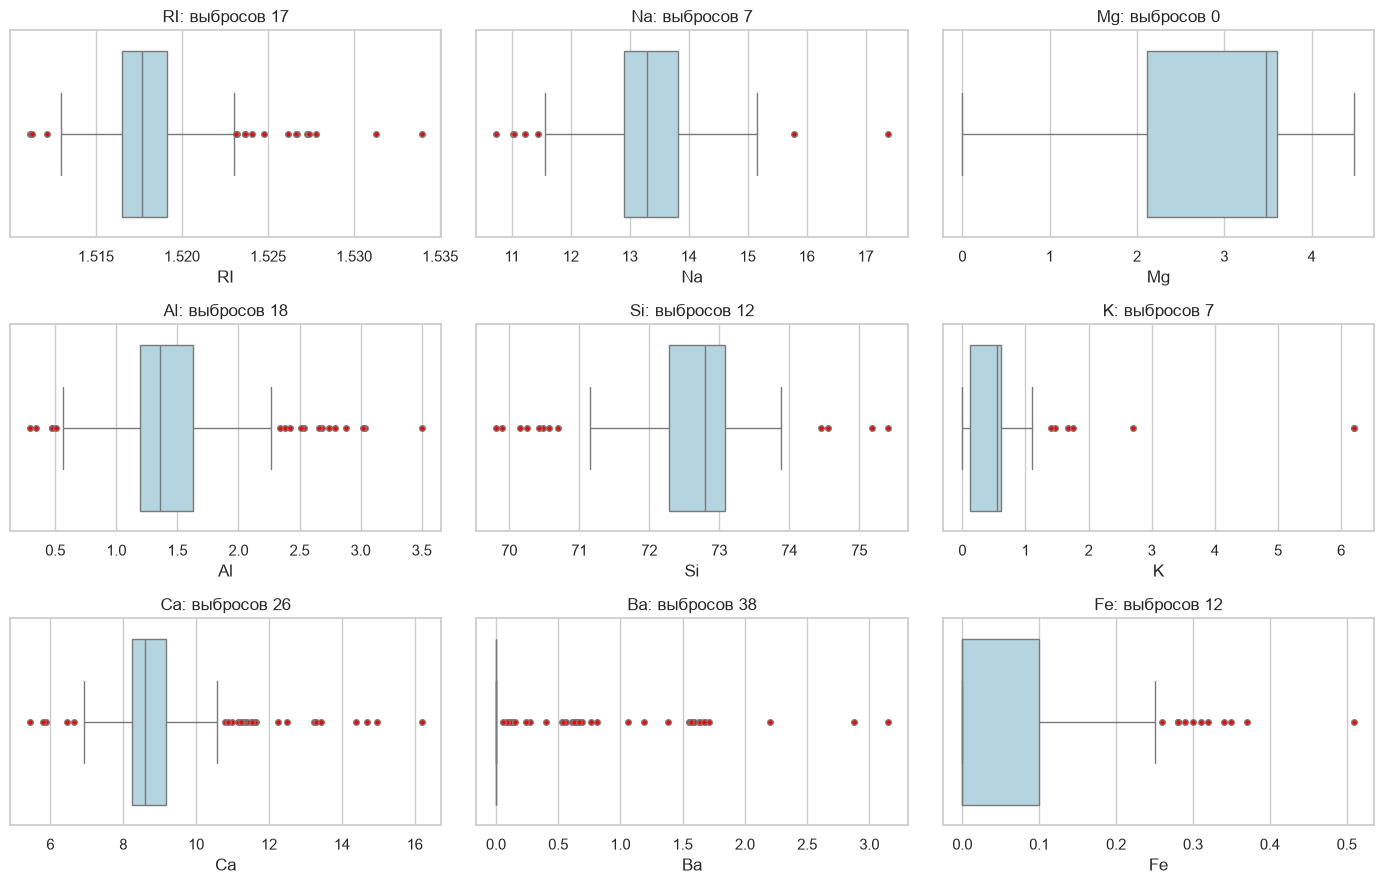

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for a, f in zip(axes.ravel(), FEATURES):
    sns.boxplot(x=df[f], ax=a, color="lightblue", flierprops=dict(marker="o", markerfacecolor="red", markersize=4))
    q1, q3 = df[f].quantile([.25, .75]); i = q3 - q1
    n = ((df[f] < q1 - 1.5 * i) | (df[f] > q3 + 1.5 * i)).sum()
    a.set_title(f"{f}: выбросов {n}")
plt.tight_layout(); plt.show()

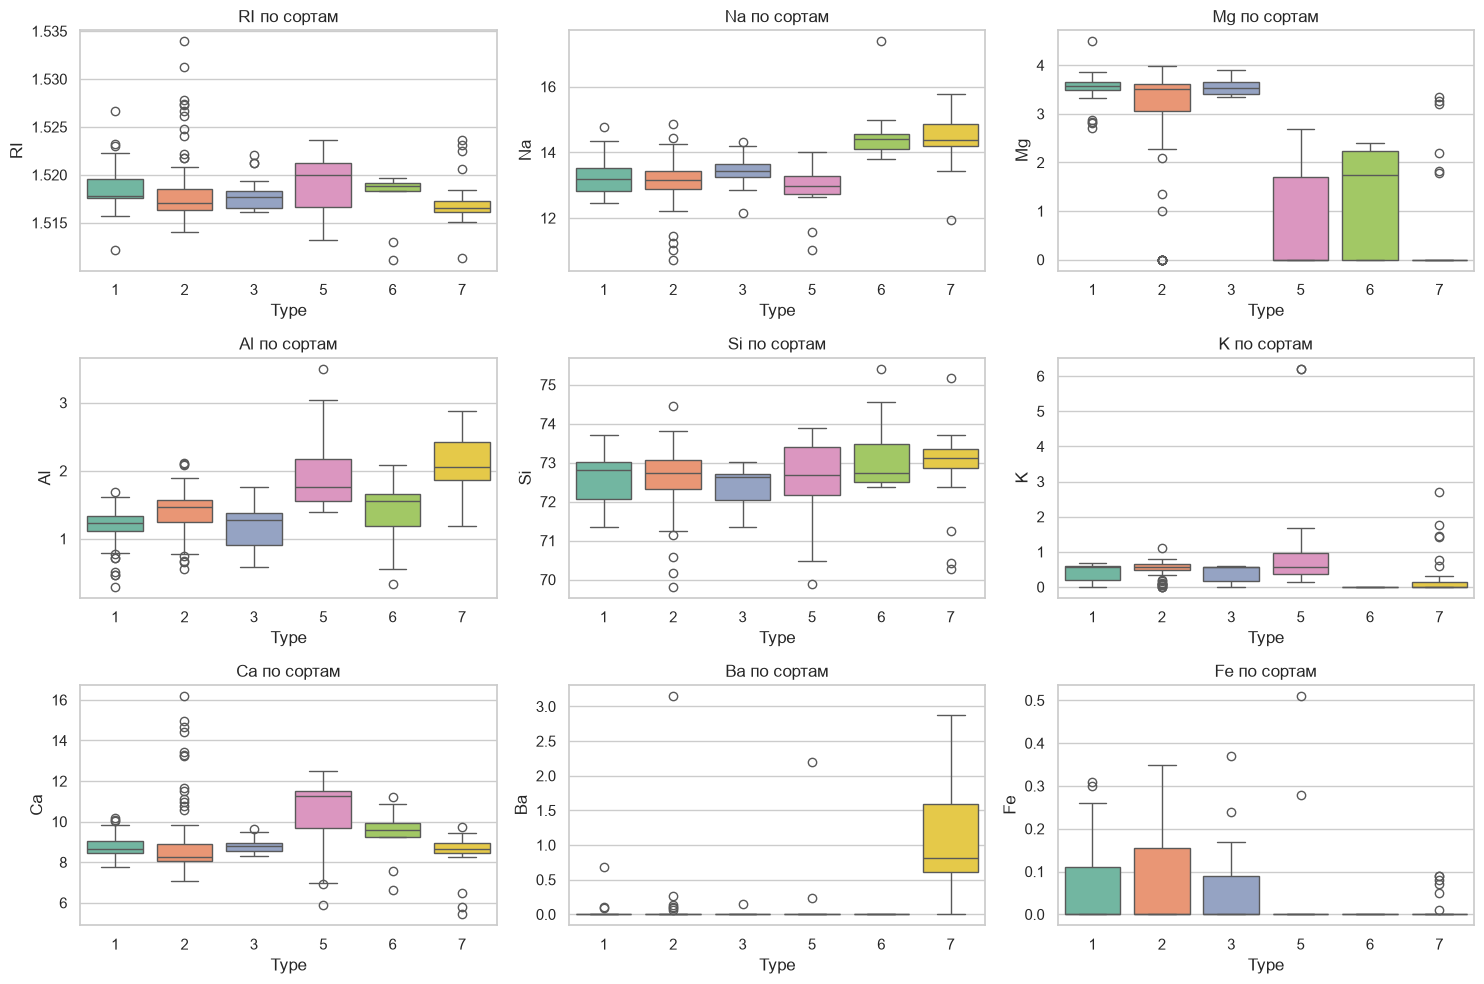

In [ ]:
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for a, f in zip(axes.ravel(), FEATURES):
    sns.boxplot(data=df, x="Type", y=f, ax=a, palette="Set2")
    a.set_title(f"{f} по сортам")
plt.tight_layout(); plt.show()

**Вывод по «ящикам».** Больше всего выбросов у Ba, K, Fe, Ca, RI и Na. Но в разрезе сортов видно, что многие из них не ошибки: высокий Ba характерен для сорта 7 (фары), высокий K — для сортов 5 (контейнеры) и 7, Fe-выбросы относятся к окнам и контейнерам. Поэтому «вылетающие» точки на общей диаграмме — это отдельные классы, и удалять их нельзя; грубые ошибки отсутствуют.

### 5. Тепловая карта корреляций

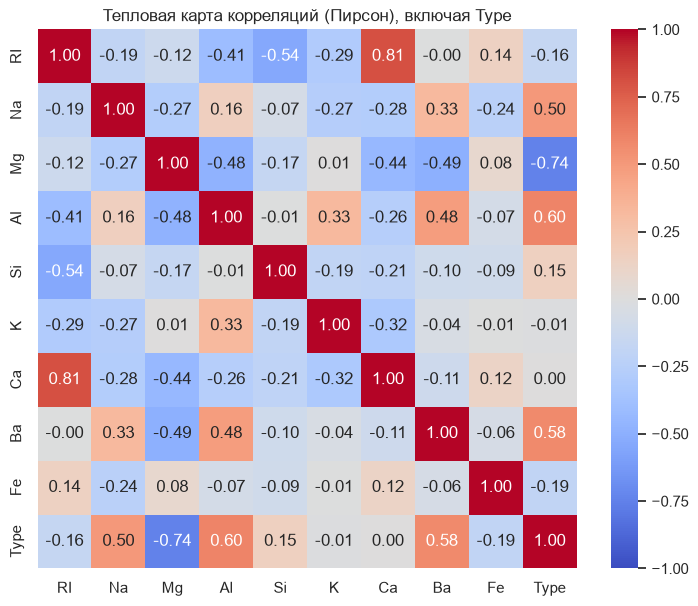

In [ ]:
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Тепловая карта корреляций (Пирсон), включая Type"); plt.show()

**Вывод по тепловой карте.** Самая сильная положительная связь — RI и Ca (≈ 0.81): оксид кальция повышает показатель преломления. Заметная отрицательная связь RI–Si (≈ −0.54) и Mg–Al, Mg–Ba, Mg–Ca (от −0.44 до −0.49). С сортом (Type) наиболее связаны Mg (≈ −0.74), Al (≈ 0.60), Ba (≈ 0.58) и Na (≈ 0.50); K и Ca с Type почти не связаны линейно. Мультиколлинеарность выражена умеренно (максимум у пары RI–Ca), поэтому при отборе признаков (ЛР 7) потребуется её учесть.

### 4.2. Визуализация в Plotly

In [ ]:
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "colab" if "google.colab" in __import__("sys").modules else "notebook_connected"
d = df.copy(); d["Сорт"] = d["Type"].map(TYPE_NAMES)
px.histogram(d, x="Mg", color="Сорт", nbins=30, barmode="overlay", opacity=.7, title="Plotly: гистограмма Mg по сортам").show()
px.box(d, x="Сорт", y="Ba", color="Сорт", title="Plotly: ящик Ba по сортам").show()
px.scatter(d, x="Ca", y="RI", color="Сорт", size="Al", hover_data=["Mg", "Na", "Ba"], title="Plotly: RI vs Ca (размер = Al)").show()
px.imshow(df.corr().round(2), text_auto=True, color_continuous_scale="RdBu_r", zmin=-1, zmax=1, title="Plotly: тепловая карта корреляций").show()

## Общий вывод
Построены гистограммы по всем 9 признакам, «ящики с усами» (общие и по сортам), тепловая карта и дополнительные виды графиков (столбчатая, круговая, рассеяния, violin, pairplot, интерактивные Plotly). Главные закономерности: Mg, Al, Ba и Na лучше всего разделяют сорта стекла; RI тесно связан с Ca и Si; Ba, K, Fe имеют скошенные распределения с «выбросами», которые на деле являются признаками отдельных сортов.